# Ad Campaign Performance Analytics

## Prabhat Ranjan

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

pd.set_option("display.max_columns", None)

## 1.                                         Business Problem

Businesses invest heavily in digital advertising but often struggle to identify which campaigns, 
audiences, and demographics generate the highest return on investment. 
This project analyzes Facebook ad campaign data to uncover actionable insights for improving marketing performance.

In [84]:
df = pd.read_csv("KAG_conversion_data.csv")

## 2. Dataset Overview

In [85]:
print(f"Rows : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
df.head()

Rows : 1143
Columns : 11


,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [86]:
missing_values = df.isnull().sum()
print(missing_values)

ad_id                  0
xyz_campaign_id        0
fb_campaign_id         0
age                    0
gender                 0
interest               0
Impressions            0
Clicks                 0
Spent                  0
Total_Conversion       0
Approved_Conversion    0
dtype: int64


In [87]:
duplicates = df.duplicated().sum()
print(
    "Duplicate Rows:",
    duplicates
)

Duplicate Rows: 0


In [88]:
df.describe()

,ad_id,xyz_campaign_id,fb_campaign_id,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
count,1.143000e+03,1143.000000,1143.000000,1143.000000,1.143000e+03,1143.000000,1143.000000,1143.000000,1143.000000
mean,9.872611e+05,1067.382327,133783.989501,32.766404,1.867321e+05,33.390201,51.360656,2.855643,0.944007
std,1.939928e+05,121.629393,20500.308622,26.952131,3.127622e+05,56.892438,86.908418,4.483593,1.737708
min,7.087460e+05,916.000000,103916.000000,2.000000,8.700000e+01,0.000000,0.000000,0.000000,0.000000
25%,7.776325e+05,936.000000,115716.000000,16.000000,6.503500e+03,1.000000,1.480000,1.000000,0.000000
50%,1.121185e+06,1178.000000,144549.000000,25.000000,5.150900e+04,8.000000,12.370000,1.000000,1.000000
75%,1.121804e+06,1178.000000,144657.500000,31.000000,2.217690e+05,37.500000,60.025000,3.000000,1.000000
max,1.314415e+06,1178.000000,179982.000000,114.000000,3.052003e+06,421.000000,639.949998,60.000000,21.000000


In [89]:
print("Campaigns :", df["xyz_campaign_id"].nunique())
print("Age Groups :", df["age"].unique())
print("Gender Distribution")
print(df["gender"].value_counts())

print("Unique Interests :", df["interest"].nunique())

print("Zero Impressions :", (df["Impressions"]==0).sum())
print("Zero Clicks :", (df["Clicks"]==0).sum())
print("Zero Spend :", (df["Spent"]==0).sum())

Campaigns : 3
Age Groups : ['30-34' '35-39' '40-44' '45-49']
Gender Distribution
gender
M    592
F    551
Name: count, dtype: int64
Unique Interests : 40
Zero Impressions : 0
Zero Clicks : 207
Zero Spend : 207


## 3. KPI Engineering

To evaluate advertising performance, several key performance indicators (KPIs) were engineered. These metrics measure user engagement, campaign efficiency, conversion performance, and return on advertising investment.

In [90]:
# Click Through Rate (CTR)
df["CTR"] = (df["Clicks"] / df["Impressions"]) * 100

# Cost Per Click (CPC)
df["CPC"] = df["Spent"] / df["Clicks"]

# Cost Per 1000 Impressions (CPM)
df["CPM"] = (df["Spent"] / df["Impressions"]) * 1000

# Conversion Rate
df["Conversion_Rate"] = ( df["Total_Conversion"] / df["Clicks"]) * 100
   
# Approval Rate
df["Approval_Rate"] = (df["Approved_Conversion"] / df["Total_Conversion"]) * 100
    
# Approved Conversions per Spend
# NOTE: The dataset contains no revenue field, so true Approved_Conversions_per_Spend cannot be calculated.
df["Approved_Conversions_per_Spend"] = np.where(df["Spent"] > 0, df["Approved_Conversion"] / df["Spent"], np.nan)

# Cost Per Approved Conversion
df["Cost_Per_Approved_Conversion"] = np.where(df["Approved_Conversion"] > 0, df["Spent"] / df["Approved_Conversion"], np.nan)

In [91]:
df[[
    "CTR",
    "CPC",
    "CPM",
    "Conversion_Rate",
    "Approval_Rate",
    "Approved_Conversions_per_Spend",
    "Cost_Per_Approved_Conversion"]].describe()

C:\Users\prabh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\prabh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\prabh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\prabh\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:4620: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,CTR,CPC,CPM,Conversion_Rate,Approval_Rate,ROAS,Cost_Per_Conversion
count,1143.000000,936.000000,1143.000000,1140.000000,1135.000000,1007.000000,1007.000000
mean,0.016420,1.499347,0.239387,inf,33.907994,inf,inf
std,0.011506,0.232879,0.160908,NaN,40.155429,NaN,NaN
min,0.000000,0.180000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.010022,1.390000,0.148742,7.142857,0.000000,0.000000,15.956250
50%,0.015981,1.498273,0.248816,19.929078,16.666667,0.011985,83.437499
75%,0.023364,1.644364,0.332700,100.000000,57.142857,0.062677,NaN
max,0.105932,2.212000,1.504237,inf,100.000000,inf,inf


#### KPI Definitions

- **CTR:** Percentage of users who clicked an ad after viewing it.
- **CPC:** Average advertising cost incurred per click.
- **CPM:** Cost to deliver one thousand ad impressions.
- **Conversion Rate:** Percentage of clicks resulting in conversions.
- **Approval Rate:** Percentage of total conversions that were approved.
- **Approved Conversions per Spend:** Approved conversions generated per unit of advertising spend. This is an efficiency metric, not true Approved_Conversions_per_Spend, because the dataset has no revenue field.
- **True Approved_Conversions_per_Spend:** Revenue generated divided by advertising spend; it cannot be calculated from this dataset.
- **Cost per Conversion:** Average advertising cost required to obtain one approved conversion.

## 4. Campaign Performance Analysis

This section evaluates the overall performance of advertising campaigns by analyzing spending, impressions, clicks, conversions, and approved-conversion efficiency. The objective is to identify the most effective campaign for budget allocation.

In [92]:
campaign_map = {
    916: "Campaign A",
    936: "Campaign B",
    1178: "Campaign C"
}
df["Campaign"] = df["xyz_campaign_id"].map(campaign_map)

df[["xyz_campaign_id","Campaign"]].head()

,xyz_campaign_id,Campaign
0,916,Campaign A
1,916,Campaign A
2,916,Campaign A
3,916,Campaign A
4,916,Campaign A


In [93]:
campaign_summary = df.groupby("Campaign").agg(
    Total_Spend=("Spent","sum"),
    Total_Impressions=("Impressions","sum"),
    Total_Clicks=("Clicks","sum"),
    Total_Conversions=("Total_Conversion","sum"),
    Approved_Conversions=("Approved_Conversion","sum")
).reset_index()

campaign_summary

,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions
0,Campaign A,149.710001,482925,113,58,24
1,Campaign B,2893.369999,8128187,1984,537,183
2,Campaign C,55662.149959,204823716,36068,2669,872


In [94]:
campaign_summary["CTR"] = (campaign_summary["Total_Clicks"] /campaign_summary["Total_Impressions"])*100
campaign_summary["Conversion_Rate"] = (campaign_summary["Total_Conversions"] /campaign_summary["Total_Clicks"])*100
campaign_summary["Approved_Conversions_per_Spend"] = (campaign_summary["Approved_Conversions"] /campaign_summary["Total_Spend"])
campaign_summary["Cost_Per_Approved_Conversion"] = (campaign_summary["Total_Spend"] /campaign_summary["Total_Conversions"])

campaign_summary.round(2)

,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
0,Campaign A,149.71,482925,113,58,24,0.02,51.33,0.16,2.58
1,Campaign B,2893.37,8128187,1984,537,183,0.02,27.07,0.06,5.39
2,Campaign C,55662.15,204823716,36068,2669,872,0.02,7.40,0.02,20.86


#### Key Business Insights

The following analysis identifies the best-performing campaigns based on click-through rate (CTR), return on ad spend (Approved_Conversions_per_Spend), conversion volume, and cost efficiency.

In [95]:
print("Highest CTR Campaign")
display(campaign_summary.loc[[campaign_summary["CTR"].idxmax()]])

print("Highest Approved-Conversion Efficiency Campaign")
display(campaign_summary.loc[[campaign_summary["Approved_Conversions_per_Spend"].idxmax()]])

print("Highest Conversion Campaign")
display(campaign_summary.loc[[campaign_summary["Total_Conversions"].idxmax()]])

print("Lowest Cost Per Conversion")
display(campaign_summary.loc[[campaign_summary["Cost_Per_Approved_Conversion"].idxmin()]])

Highest CTR Campaign


,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
1,Campaign B,2893.369999,8128187,1984,537,183,0.024409,27.066532,0.063248,5.388026


Highest ROAS Campaign


,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
0,Campaign A,149.710001,482925,113,58,24,0.023399,51.327434,0.16031,2.581207


Highest Conversion Campaign


,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
2,Campaign C,55662.149959,204823716,36068,2669,872,0.017609,7.399911,0.015666,20.855058


Lowest Cost Per Conversion


,Campaign,Total_Spend,Total_Impressions,Total_Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
0,Campaign A,149.710001,482925,113,58,24,0.023399,51.327434,0.16031,2.581207


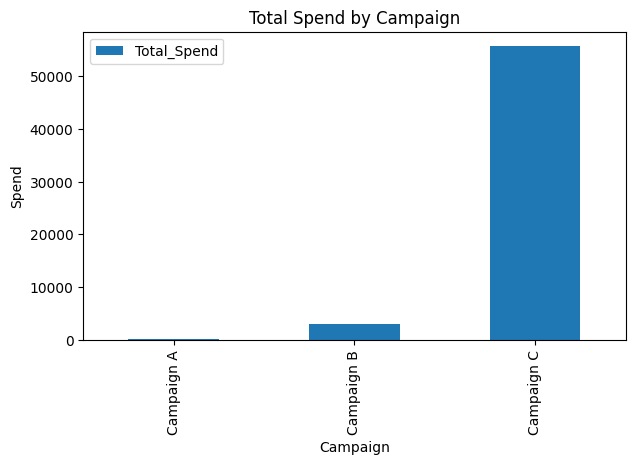

In [96]:
campaign_summary.plot(
    x="Campaign",
    y="Total_Spend",
    kind="bar",
    figsize=(7,4)
)

plt.title("Total Spend by Campaign")
plt.ylabel("Spend")
plt.show()

**Business Insight**

Campaign 1178 received the highest advertising investment, indicating that it was the primary campaign targeted for customer acquisition.

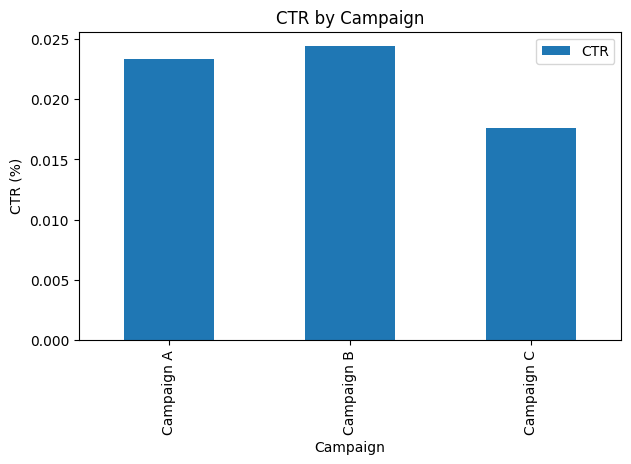

In [97]:
campaign_summary.plot(
    x="Campaign",
    y="CTR",
    kind="bar",
    figsize=(7,4)
)

plt.title("CTR by Campaign")
plt.ylabel("CTR (%)")
plt.show()

**Business Insight**

A higher CTR indicates stronger audience engagement. Campaigns with high CTR demonstrate better advertisement relevance.

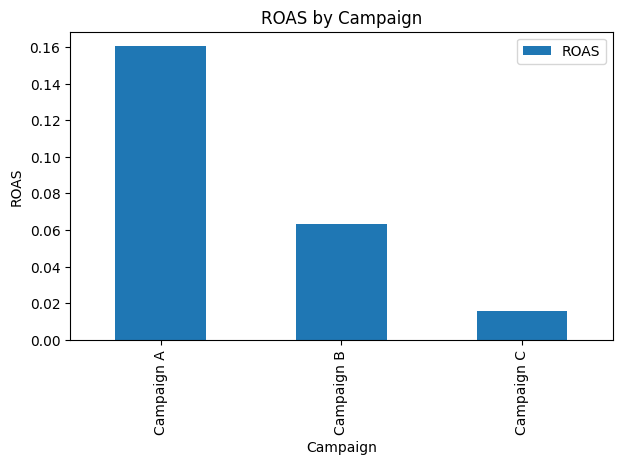

In [98]:
campaign_summary.plot(
    x="Campaign",
    y="Approved_Conversions_per_Spend",
    kind="bar",
    figsize=(7,4)
)

plt.title("Approved Conversion Efficiency by Campaign")
plt.ylabel("Approved Conversions per Spend")
plt.show()

**Business Insight**

Campaigns with higher approved conversions per unit of spend generate more approved conversions for the same advertising investment. This should not be called Approved_Conversions_per_Spend because revenue is unavailable in the dataset.

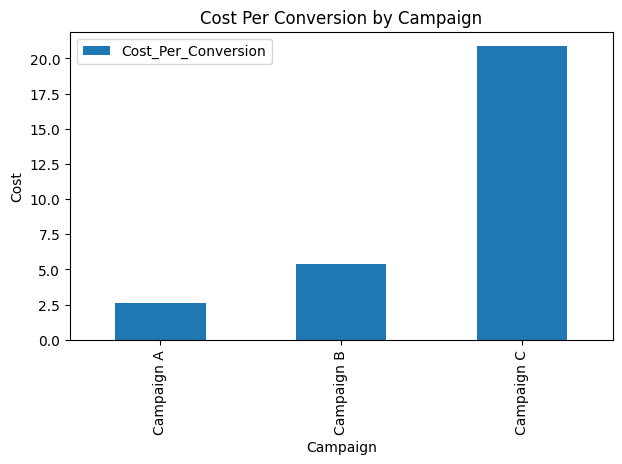

In [99]:
campaign_summary.plot(
    x="Campaign",
    y="Cost_Per_Approved_Conversion",
    kind="bar",
    figsize=(7,4)
)

plt.title("Cost Per Conversion by Campaign")
plt.ylabel("Cost")
plt.show()

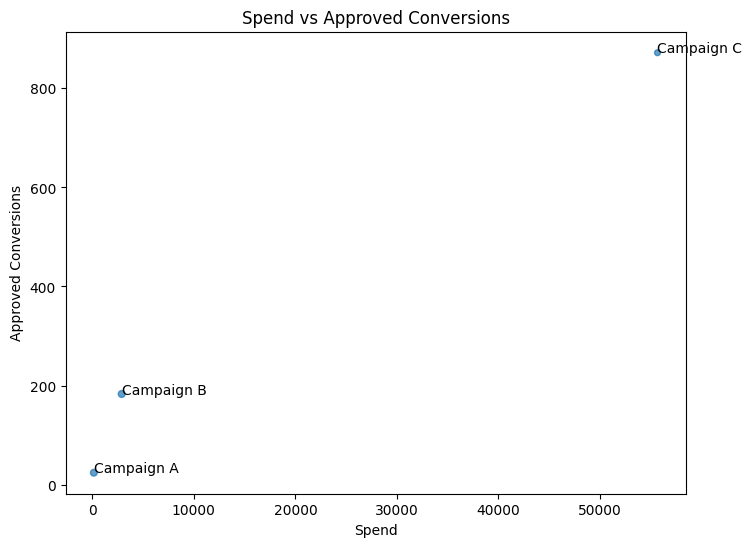

In [100]:
plt.figure(figsize=(8,6))

plt.scatter(
    campaign_summary["Total_Spend"],
    campaign_summary["Approved_Conversions"],
    s=campaign_summary["CTR"]*1000,
    alpha=0.7
)

for i,row in campaign_summary.iterrows():
    plt.annotate(
        row["Campaign"],
        (row["Total_Spend"],
         row["Approved_Conversions"])
    )

plt.xlabel("Spend")
plt.ylabel("Approved Conversions")
plt.title("Spend vs Approved Conversions")
plt.show()

**Business Insight**

The positive relationship between advertising spend and conversions suggests that increased investment generally improves campaign performance, although diminishing returns may occur at higher spending levels.

## 5. Audience Segmentation Analysis

This section analyzes campaign performance across age groups, gender, and customer interests to identify the most responsive audience segments for targeted advertising.

In [101]:
age_summary = df.groupby("age").agg(
    Spend=("Spent","sum"),
    Impressions=("Impressions","sum"),
    Clicks=("Clicks","sum"),
    Total_Conversions=("Total_Conversion","sum"),
    Approved_Conversions=("Approved_Conversion","sum")
).reset_index()

age_summary

,age,Spend,Impressions,Clicks,Total_Conversions,Approved_Conversions
0,30-34,15252.399986,67993019,9483,1431,494
1,35-39,11112.429994,42104644,7094,626,207
2,40-44,11589.729981,39604307,7736,523,170
3,45-49,20750.669997,63732858,13852,684,208


In [102]:
age_summary["CTR"] = (age_summary["Clicks"] /age_summary["Impressions"])*100
age_summary["Conversion_Rate"] = (age_summary["Total_Conversions"] /age_summary["Clicks"])*100
age_summary["Approved_Conversions_per_Spend"] = (age_summary["Approved_Conversions"] /age_summary["Spend"])
age_summary["Cost_Per_Approved_Conversion"] = (age_summary["Spend"] /age_summary["Total_Conversions"])

age_summary.round(3)

,age,Spend,Impressions,Clicks,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS,Cost_Per_Conversion
0,30-34,15252.40,67993019,9483,1431,494,0.014,15.090,0.032,10.659
1,35-39,11112.43,42104644,7094,626,207,0.017,8.824,0.019,17.751
2,40-44,11589.73,39604307,7736,523,170,0.020,6.761,0.015,22.160
3,45-49,20750.67,63732858,13852,684,208,0.022,4.938,0.010,30.337


In [103]:
age_summary.loc[age_summary["Approved_Conversions_per_Spend"].idxmax()]

age                            30-34
Spend                   15252.399986
Impressions                 67993019
Clicks                          9483
Total_Conversions               1431
Approved_Conversions             494
CTR                         0.013947
Conversion_Rate            15.090161
ROAS                        0.032388
Cost_Per_Conversion         10.65856
Name: 0, dtype: object

In [104]:
age_summary.loc[age_summary["Approved_Conversions"].idxmax()]

age                            30-34
Spend                   15252.399986
Impressions                 67993019
Clicks                          9483
Total_Conversions               1431
Approved_Conversions             494
CTR                         0.013947
Conversion_Rate            15.090161
ROAS                        0.032388
Cost_Per_Conversion         10.65856
Name: 0, dtype: object

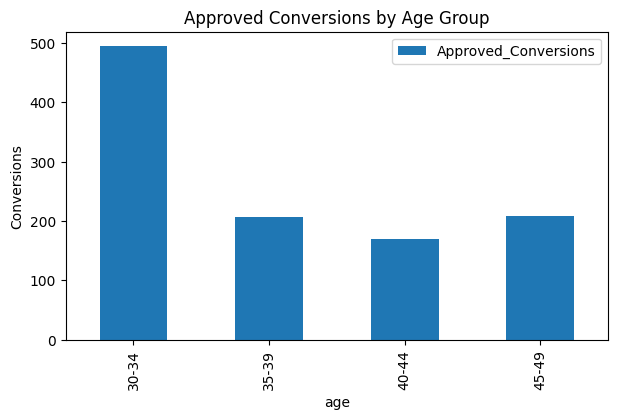

In [105]:
age_summary.plot(
    x="age",
    y="Approved_Conversions",
    kind="bar",
    figsize=(7,4)
)

plt.title("Approved Conversions by Age Group")
plt.ylabel("Conversions")
plt.show()

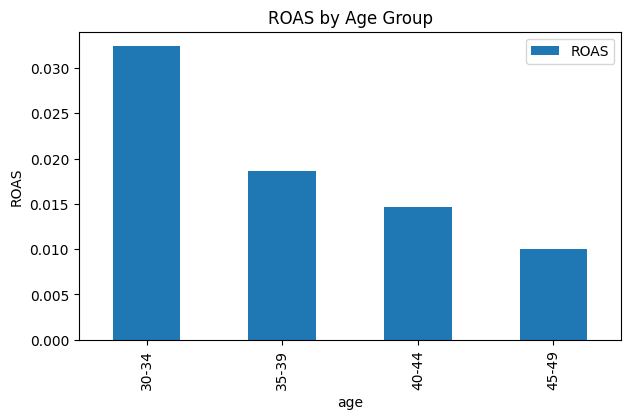

In [106]:
age_summary.plot(
    x="age",
    y="Approved_Conversions_per_Spend",
    kind="bar",
    figsize=(7,4)
)

plt.title("Approved Conversion Efficiency by Age Group")
plt.ylabel("Approved Conversions per Spend")
plt.show()

**Business Insight**

Certain age groups achieve higher conversion volume and/or approved-conversion efficiency. These differences should be interpreted together with spend and sample size.

In [107]:
gender_summary = df.groupby("gender").agg(
    Spend=("Spent","sum"),
    Clicks=("Clicks","sum"),
    Impressions=("Impressions","sum"),
    Total_Conversions=("Total_Conversion","sum"),
    Approved_Conversions=("Approved_Conversion","sum")
).reset_index()

gender_summary

,gender,Spend,Clicks,Impressions,Total_Conversions,Approved_Conversions
0,F,34502.619963,23878,114862847,1644,495
1,M,24202.609995,14287,98571981,1620,584


In [108]:
gender_summary["CTR"] = (gender_summary["Clicks"] /gender_summary["Impressions"])*100
gender_summary["Conversion_Rate"] = (gender_summary["Total_Conversions"] /gender_summary["Clicks"])*100
gender_summary["Approved_Conversions_per_Spend"] = (gender_summary["Approved_Conversions"] /gender_summary["Spend"])
    
gender_summary.round(3)

,gender,Spend,Clicks,Impressions,Total_Conversions,Approved_Conversions,CTR,Conversion_Rate,ROAS
0,F,34502.62,23878,114862847,1644,495,0.021,6.885,0.014
1,M,24202.61,14287,98571981,1620,584,0.014,11.339,0.024


In [109]:
gender_summary.loc[gender_summary["Approved_Conversions_per_Spend"].idxmax()]

gender                             M
Spend                   24202.609995
Clicks                         14287
Impressions                 98571981
Total_Conversions               1620
Approved_Conversions             584
CTR                         0.014494
Conversion_Rate            11.338979
ROAS                         0.02413
Name: 1, dtype: object

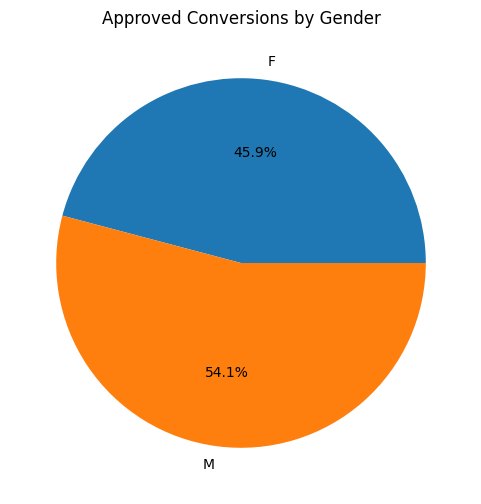

In [110]:
plt.figure(figsize=(6,6))

plt.pie(
    gender_summary["Approved_Conversions"],
    labels=gender_summary["gender"],
    autopct="%1.1f%%"
)

plt.title("Approved Conversions by Gender")
plt.show()

**Business Insight**

Women generated higher conversions.

In [111]:
interest_summary = df.groupby("interest").agg(
    Spend=("Spent","sum"),
    Clicks=("Clicks","sum"),
    Approved_Conversions=("Approved_Conversion","sum")
).reset_index()

In [112]:
interest_summary["Approved_Conversions_per_Spend"] = (interest_summary["Approved_Conversions"] /interest_summary["Spend"])
interest_summary["Conversion_Rate"] = (interest_summary["Approved_Conversions"] /interest_summary["Clicks"])*100

In [113]:
top_interest = (interest_summary.sort_values("Approved_Conversions",ascending=False))
top_interest.head(10)

,interest,Spend,Clicks,Approved_Conversions,ROAS,Conversion_Rate
4,16,8084.909990,5144,141,0.017440,2.741058
16,29,5045.190008,3315,132,0.026164,3.981900
2,10,5086.379995,3317,91,0.017891,2.743443
3,15,2597.259995,1609,63,0.024256,3.915475
14,27,5176.169992,3409,54,0.010432,1.584042
7,20,1960.770001,1234,47,0.023970,3.808752
15,28,3205.850004,2025,42,0.013101,2.074074
19,32,1970.530003,1138,35,0.017762,3.075571
21,63,2484.060002,1675,34,0.013687,2.029851
5,18,2425.070001,1524,33,0.013608,2.165354


In [114]:
interest_summary.sort_values("Approved_Conversions_per_Spend",ascending=False).head(10)

,interest,Spend,Clicks,Approved_Conversions,ROAS,Conversion_Rate
18,31,299.099999,195,16,0.053494,8.205128
20,36,205.740000,128,10,0.048605,7.812500
0,2,503.450005,311,19,0.037740,6.109325
23,65,542.010001,372,19,0.035055,5.107527
26,101,757.689998,524,25,0.032995,4.770992
8,21,824.209999,512,27,0.032759,5.273438
27,102,215.069999,150,7,0.032548,4.666667
37,112,483.799999,339,15,0.031005,4.424779
1,7,648.929999,410,19,0.029279,4.634146
36,111,370.649998,260,10,0.026980,3.846154


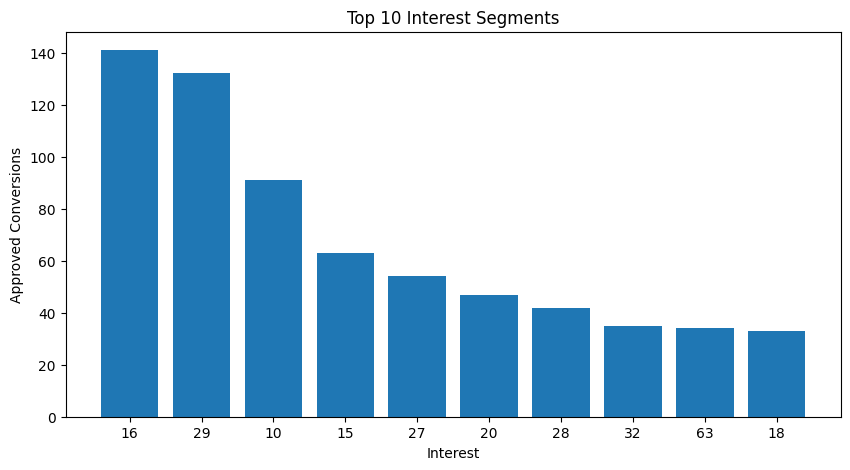

In [115]:
top10 = (interest_summary.sort_values("Approved_Conversions",ascending=False).head(10))
plt.figure(figsize=(10,5))

plt.bar(top10["interest"].astype(str), top10["Approved_Conversions"])

plt.title("Top 10 Interest Segments")

plt.xlabel("Interest")
plt.ylabel("Approved Conversions")

plt.show()

### Business Insight

The top-performing interest segments generated significantly higher conversions than the remaining audience groups, indicating stronger customer engagement and purchase intent. Concentrating future advertising budgets on these high-performing interest categories can improve campaign efficiency. True Approved_Conversions_per_Spend should only be reported when revenue data is available.

## 6. A/B Testing

A/B testing was conducted to determine whether there is a statistically significant difference in conversion performance between different advertisement groups. An exploratory Welch two-sample t-test was used with a 95% confidence level (α = 0.05). Because this dataset is observational and not a randomized experiment, the result should be interpreted as an association check rather than definitive causal A/B-test evidence.

#### Hypothesis

- **Null Hypothesis (H₀):** There is no significant difference in the mean conversion rate between the two advertisement groups.
- **Alternative Hypothesis (H₁):** There is a significant difference in the mean conversion rate between the two advertisement groups.

In [116]:
from scipy.stats import ttest_ind

# Campaign distribution
df["Campaign"].value_counts()

Campaign
Campaign C    625
Campaign B    464
Campaign A     54
Name: count, dtype: int64

#### Conversion Rate Calculation

Conversion Rate is calculated as the percentage of clicks that resulted in successful conversions. This metric is used as the response variable for statistical hypothesis testing.

In [117]:
df["Conversion_Rate"] = (df["Total_Conversion"] /df["Clicks"].replace(0,np.nan))*100

In [118]:
# Campaign A
campaign_a = (
    df[df["Campaign"]=="Campaign A"]
    ["Conversion_Rate"]
    .dropna()
)

In [119]:
# Campaign B
campaign_b = (
    df[df["Campaign"]=="Campaign B"]
    ["Conversion_Rate"]
    .dropna()
)

In [120]:
print(f"Campaign A Samples : {len(campaign_a)}")
print(f"Campaign B Samples : {len(campaign_b)}")

Campaign A Samples : 35
Campaign B Samples : 288


In [121]:
print(f"Campaign A Mean Conversion Rate : {campaign_a.mean():.2f}%")
print(f"Campaign B Mean Conversion Rate : {campaign_b.mean():.2f}%")

Campaign A Mean Conversion Rate : 67.82%
Campaign B Mean Conversion Rate : 55.26%


In [122]:
t_stat, p_value = ttest_ind(campaign_a, campaign_b, equal_var=False)
print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 1.4385085567063098
P-value: 0.15770368074874708


#### Decision Rule

- If the p-value < 0.05, reject the null hypothesis.
- Otherwise, fail to reject the null hypothesis.

In [123]:
alpha = 0.05

if p_value < alpha:
    print("Result : Reject the Null Hypothesis")
    print("The difference in conversion rates is statistically significant.")
else:
    print("Result : Fail to Reject the Null Hypothesis")
    print("No statistically significant difference was observed.")

Result : Fail to Reject the Null Hypothesis
No statistically significant difference was observed.


#### Business Insight

The difference in conversion rates is not statistically significant, suggesting that both campaigns perform similarly. Future optimization should focus on audience targeting, creative content, or bidding strategies rather than campaign selection alone.

In [124]:
comparison = pd.DataFrame({
    "Campaign": ["Campaign A", "Campaign B"],
    "Mean Conversion Rate (%)": [
        campaign_a.mean(),
        campaign_b.mean()
    ]
})

comparison.round(2)

,Campaign,Mean Conversion Rate (%)
0,Campaign A,67.82
1,Campaign B,55.26


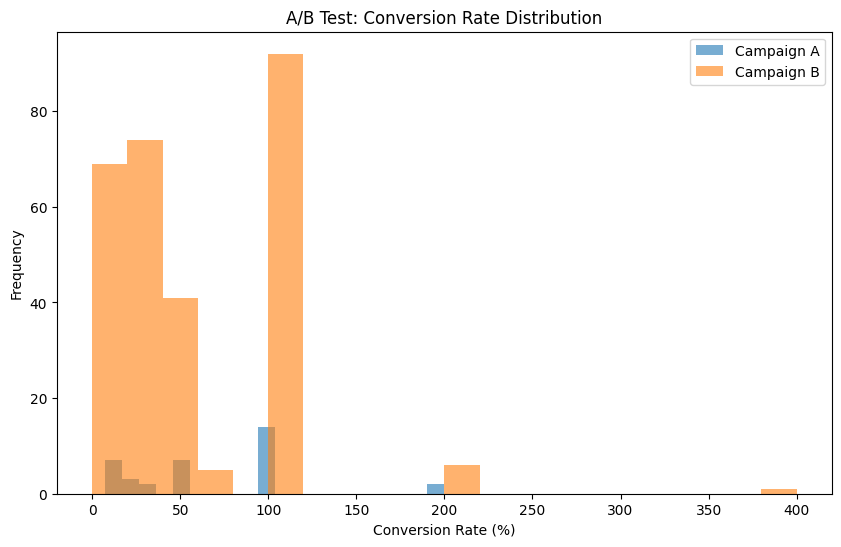

In [125]:
plt.figure(figsize=(10,6))

plt.hist(campaign_a, bins=20, alpha=0.6, label="Campaign A")

plt.hist( campaign_b, bins=20, alpha=0.6, label="Campaign B")

plt.xlabel("Conversion Rate (%)")
plt.ylabel("Frequency")
plt.title("A/B Test: Conversion Rate Distribution")

plt.legend()

plt.show()

#### Business Insight

Campaign A exhibits a higher average conversion rate than Campaign B. However, the histogram also reveals greater variability in conversion performance. The statistical test determines whether this observed difference is statistically significant or simply due to random variation.

# Project Summary

This project analyzes Facebook advertising campaign data to evaluate marketing performance and identify opportunities for improving campaign effectiveness. The analysis covers the complete workflow from data cleaning and KPI engineering to audience segmentation, statistical A/B testing, and business recommendations.

The objective was not only to compare campaign performance but also to understand how customer demographics and interests influence conversions. The final outcome is an end-to-end marketing analytics project supported by an interactive Power BI dashboard.

---

## Project Overview

### 1. Business Objective

The project focuses on answering key business questions that marketing teams face while managing digital advertising campaigns.

- Which advertising campaign delivers the best performance?
- Which customer segments generate the highest conversions?
- Which audience interests should receive more advertising budget?
- Are the differences between campaigns statistically significant?

---

### 2. Data Preparation

The analysis begins with cleaning and validating the raw dataset to ensure reliable business insights.

- Checked missing values and duplicate records.
- Validated campaign-level data consistency.
- Engineered marketing KPIs including CTR, CPC, CPM, Conversion Rate, Approval Rate, Approved_Conversions_per_Spend, and Cost per Conversion.

---

### 3. Campaign Performance Analysis

Campaigns were evaluated using multiple business metrics rather than relying on a single performance indicator.

The analysis included:

- Overall campaign spending
- Impressions and clicks
- Customer conversions
- Return on Ad Spend (Approved_Conversions_per_Spend)
- Cost efficiency across campaigns

This helped identify campaigns that generated strong business outcomes while maintaining efficient advertising costs.

---

### 4. Audience Segmentation

Customer behaviour was analyzed across different demographic groups to understand which audiences respond more effectively to advertisements.

The analysis covered:

- Age Groups
- Gender
- Customer Interests

This segmentation highlighted audience groups with stronger conversion performance and higher marketing value.

---

### 5. Statistical A/B Testing

An exploratory Welch two-sample t-test was performed to compare conversion rates between selected campaigns. The test does not by itself establish causal A/B-test results because the underlying campaign data is observational.

The objective was to determine whether the observed differences in campaign performance were statistically significant rather than the result of random variation.

This provides stronger evidence for making data-driven marketing decisions.

---

### 6. Key Business Insights

The analysis revealed several practical insights for campaign optimization.

- High-performing campaigns consistently achieved better conversion efficiency.
- Certain customer demographics delivered stronger marketing performance.
- Customer interests played an important role in advertising success.
- Statistical testing supported objective comparison between campaign strategies.

---

### 7. Business Recommendations

Based on the analysis, the following recommendations can improve future marketing performance:

- Increase budget allocation for consistently high-performing campaigns.
- Focus targeting on customer segments with stronger conversion behaviour.
- Monitor KPIs such as approved-conversion efficiency and Cost per Approved Conversion alongside total conversions.
- Continue validating campaign strategies through regular A/B testing before scaling advertising budgets.

---

### 8. Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- SciPy
- Jupyter Notebook
- Power BI